In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [104]:
df = pd.read_csv("D:\\Data science\\codes\\files\\Shopping_data.csv")
display(df.head())
X=df.iloc[:,3:]

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


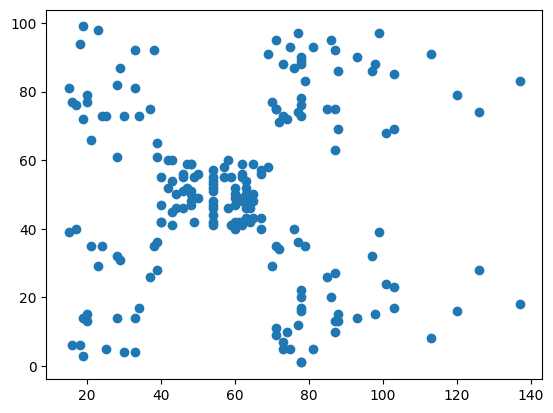

In [105]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,1:2])
plt.show()

# Agglomerative Clustring

### Single

In [15]:
model = AgglomerativeClustering(n_clusters=5, linkage='single')
df["single"] = model.fit_predict(X)

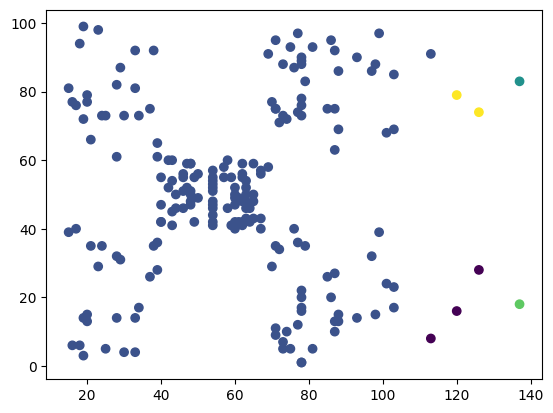

In [16]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,1:2], c=df["single"])
plt.show()

In [17]:
score = silhouette_score(X, df["single"])
print("Single - score:",np.round(score,2))

Single - score: 0.27


score is not good so we ignore single linkage

### Complete

In [19]:
model = AgglomerativeClustering(n_clusters=5, linkage='complete')
df["complete"] = model.fit_predict(X)

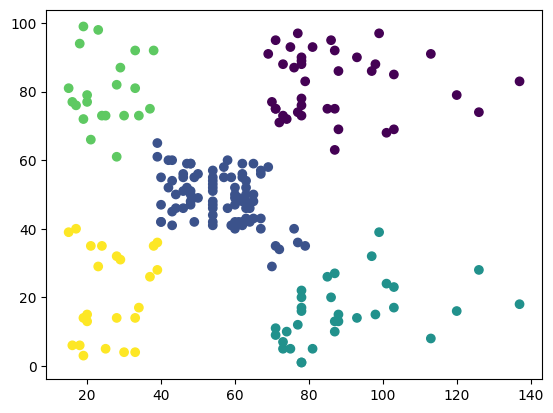

In [20]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,1:2], c=df["complete"])
plt.show()

In [21]:
score = silhouette_score(X, df["complete"])
print("Single - score:",np.round(score,2))

Single - score: 0.55


score is somewhat good than single

### Average

In [22]:
model = AgglomerativeClustering(n_clusters=5, linkage='average')
df["average"] = model.fit_predict(X)

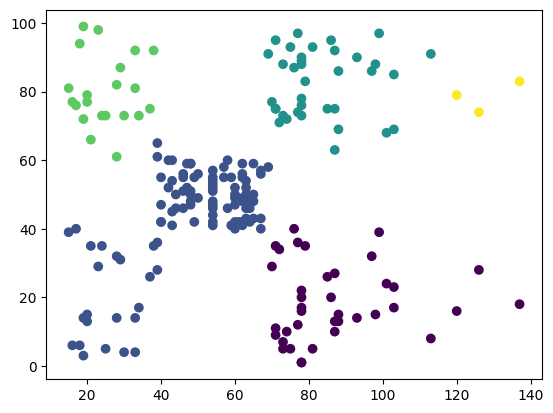

In [23]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,1:2], c=df["average"])
plt.show()

In [24]:
score = silhouette_score(X, df["average"])
print("Single - score:",np.round(score,2))

Single - score: 0.48


better than single but not complete

### Ward

In [66]:
model = AgglomerativeClustering(n_clusters=5, linkage='ward')
df["ward"] = model.fit_predict(X)

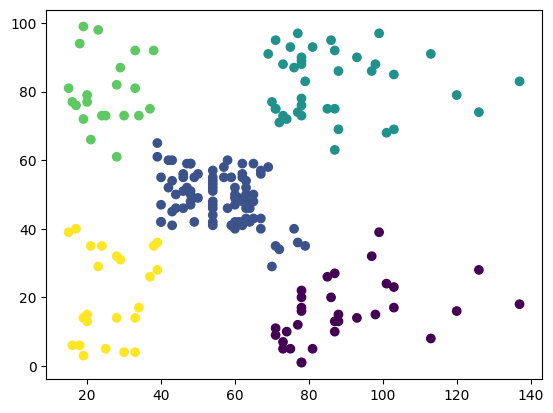

In [67]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,1:2], c=df["ward"])
plt.show()

In [68]:
score = silhouette_score(X, df["ward"])
print("Single - score:",np.round(score,2))

Single - score: 0.55


no change as complete

In [73]:
scores = []
for i in range(2,11):
    model = AgglomerativeClustering(n_clusters=i, linkage='ward')
    df["ward"] = model.fit_predict(X)
    scores.append(silhouette_score(X, df["ward"]))

scores = pd.DataFrame(scores, index=range(2,11), columns=["score"])
scores


,score
2,0.367064
3,0.461834
4,0.491660
5,0.552995
6,0.538021
7,0.519905
8,0.432629
9,0.438925
10,0.434266


##### for changing n_cluster numbers

In [28]:
scores = []
for i in range(2,11):
    model = AgglomerativeClustering(n_clusters=i, linkage='ward')
    df["ward"] = model.fit_predict(X)
    score = silhouette_score(X, df["ward"])
    scores.append(score)


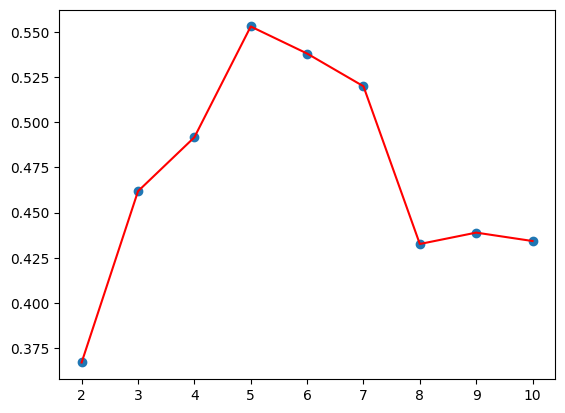

In [29]:
plt.scatter(range(2,11), scores)
plt.plot(range(2,11), scores, color='red')
plt.show()

# K-means Clustring

In [81]:
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [82]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 5)
df["Kmeans"] = model.fit_predict(X)

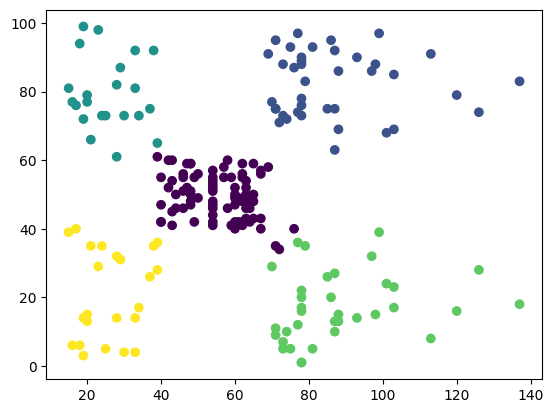

In [83]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,1:2], c=df["Kmeans"])
plt.show()

In [84]:
score = silhouette_score(X, df["Kmeans"])
print("Kmeans - score:",np.round(score,2))

Kmeans - score: 0.55


In [85]:
scores = []
for i in range(2,11):
    model = KMeans(n_clusters=i)
    df["Kmeans"] = model.fit_predict(X)
    scores.append(silhouette_score(X, df["Kmeans"]))
    

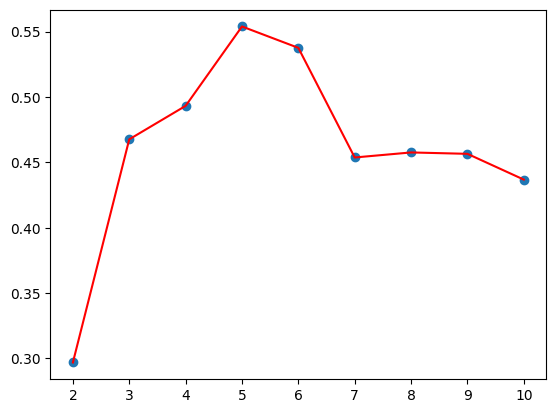

In [86]:
plt.scatter(range(2,11), scores)
plt.plot(range(2,11), scores, color='red')
plt.show()

# DBSCAN

In [98]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

In [106]:
ss = StandardScaler()
ss_X = ss.fit_transform(X)


In [138]:
model = DBSCAN(eps=0.5, min_samples=3)
df["DBSCAN"] = model.fit_predict(ss_X)

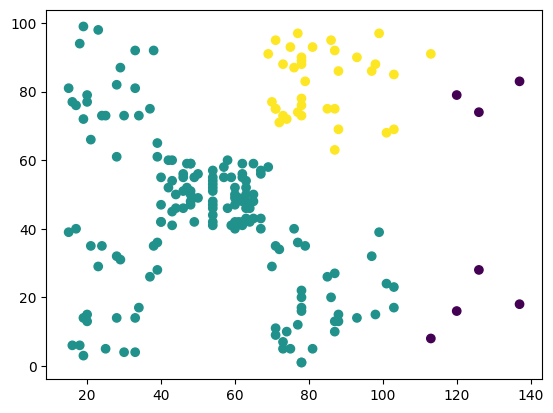

In [139]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,1:2], c=df["DBSCAN"])
plt.show()

In [140]:
score = silhouette_score(X, df["DBSCAN"])
print("DBSCAN - score:",np.round(score,2))

DBSCAN - score: 0.36


In [141]:
df["DBSCAN"].value_counts()

 0    157
 1     36
-1      7
Name: DBSCAN, dtype: int64

DBSCAN has -1 as a cluster which means noise and outliers  
that says DBSCAN was successfull in detecting outliers
so we can use DBSCAN for removing outliers and use aggramative for cluster forming

In [144]:
df[df["DBSCAN"] == -1]

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),DBSCAN
192,193,Male,33,113,8,-1
194,195,Female,47,120,16,-1
195,196,Female,35,120,79,-1
196,197,Female,45,126,28,-1
197,198,Male,32,126,74,-1
198,199,Male,32,137,18,-1
199,200,Male,30,137,83,-1


In [145]:
df[df["DBSCAN"] != -1]

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),DBSCAN
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
...,...,...,...,...,...,...
188,189,Female,41,103,17,0
189,190,Female,36,103,85,1
190,191,Female,34,103,23,0
191,192,Female,32,103,69,1


In [147]:
df_new = df[df["DBSCAN"] != -1]
df_new

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),DBSCAN
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
...,...,...,...,...,...,...
188,189,Female,41,103,17,0
189,190,Female,36,103,85,1
190,191,Female,34,103,23,0
191,192,Female,32,103,69,1


for clustring better start with dbscan (if good results continue else remove outliers then go for aggramative or K-means)

now we can use cluster as target varible and fit any supervised models